# SCORE-Net: Inference Speed, Resource Profile, and Hardware Benchmark

This notebook measures SCORE-Net inference latency, throughput, and parameter efficiency on four benchmark datasets (**COMPAS**, **German Credit**, **UCI Adult**, **Synthetic**).

### All numbers are read from artifacts

* SCORE-Net checkpoints are loaded from `models/<dataset>/`; the architecture (`H_init`, feature and class counts) is inferred from the `state_dict`.
* Baseline results are read from `results/baselines_{compas,german,adult}.csv`, produced by the comparison notebooks under `notebooks/01_baselines.ipynb`.
* No accuracy, latency, or model count is hard-coded in this notebook.

### Methodological principles

1. **Fair CPU comparison:** all baseline models run on CPU, so SCORE-Net is also measured on the same CPU hardware; GPU results are reported as an additional advantage.
2. **Two-stage regime:** batch inference represents throughput, while single-sample (batch=1) inference represents online latency in production.
3. **Statistical reliability:** measurements are repeated after warmup iterations and reported as mean $\pm$ standard deviation. Repetition counts can be reduced with the `SCORENET_BENCH_*` environment variables (smoke tests only).

> **Run order:** training notebooks → baseline notebooks → this notebook.

In [1]:
import json
import os
import sys
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import torch
import matplotlib.pyplot as plt

# Locate the project root regardless of the notebook's working directory.
cwd = Path.cwd().resolve()
project_root = next(
    (path for path in [cwd, *cwd.parents] if (path / "utils" / "experiments.py").exists()),
    cwd.parent,
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from utils.reproducibility import set_seed
from utils.experiments import (
    DATASETS,
    FIGURE_DIR,
    compact_model,
    load_baselines,
    load_checkpoint,
    load_splits,
    save_figure,
)

set_seed(42)

# Benchmark repetitions can be reduced via environment variables (quick smoke test).
N_WARMUP = int(os.environ.get("SCORENET_BENCH_WARMUP", "50"))
N_BATCH_RUNS = int(os.environ.get("SCORENET_BENCH_BATCH_RUNS", "100"))
N_SINGLE_RUNS = int(os.environ.get("SCORENET_BENCH_SINGLE_RUNS", "500"))

output_fig_dir = FIGURE_DIR
output_fig_dir.mkdir(parents=True, exist_ok=True)

# Hardware and environment information
print("=" * 80)
print("EXPERIMENTAL ENVIRONMENT AND HARDWARE")
print("=" * 80)
print(f"Operating system         : {platform.platform()}")
print(f"CPU cores                : {psutil.cpu_count(logical=False)} physical, {psutil.cpu_count(logical=True)} logical cores")
print(f"Total system memory      : {round(psutil.virtual_memory().total / (1024**3), 2)} GB RAM")
print(f"PyTorch version          : {torch.__version__}")
has_cuda = torch.cuda.is_available()
print(f"CUDA support             : {'Available' if has_cuda else 'Unavailable'}")
if has_cuda:
    print(f"Accelerator GPU model    : {torch.cuda.get_device_name(0)}")
    print(f"GPU memory capacity      : {round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2)} GB VRAM")
print(f"Benchmark repetitions    : warmup={N_WARMUP}, batch={N_BATCH_RUNS}, single={N_SINGLE_RUNS}")
print("=" * 80)

EXPERIMENTAL ENVIRONMENT AND HARDWARE
Operating system         : Linux-7.0.0-42-generic-x86_64-with-glibc2.43
CPU cores                : 6 physical, 12 logical cores
Total system memory      : 14.93 GB RAM
PyTorch version          : 2.6.0+cu124
CUDA support             : Available
Accelerator GPU model    : NVIDIA GeForce GTX 1650
GPU memory capacity      : 3.63 GB VRAM
Benchmark repetitions    : warmup=50, batch=100, single=500


In [2]:
# ==============================================================================
# DUAL-DEVICE (CPU & GPU) BENCHMARK FUNCTION
# ==============================================================================
def benchmark_inference_dual_device(
    model_cpu,
    model_gpu,
    X_test,
    n_warmup=50,
    n_runs_batch=100,
    n_runs_single=500,
):
    # Measures inference speed on both CPU and GPU with a precise timer
    # (time.perf_counter) and CUDA synchronization.
    n_samples = X_test.shape[0]
    X_cpu = X_test.cpu()
    single_cpu = X_cpu[:1]

    # 1. CPU MEASUREMENTS
    model_cpu.eval()
    with torch.no_grad():
        for _ in range(n_warmup):
            _ = model_cpu(X_cpu)

    batch_times_cpu = []
    with torch.no_grad():
        for _ in range(n_runs_batch):
            t0 = time.perf_counter()
            _ = model_cpu(X_cpu)
            t1 = time.perf_counter()
            batch_times_cpu.append(t1 - t0)

    with torch.no_grad():
        for _ in range(n_warmup):
            _ = model_cpu(single_cpu)

    single_times_cpu = []
    with torch.no_grad():
        for _ in range(n_runs_single):
            t0 = time.perf_counter()
            _ = model_cpu(single_cpu)
            t1 = time.perf_counter()
            single_times_cpu.append(t1 - t0)

    cpu_b_mean = np.mean(batch_times_cpu)
    cpu_b_std = np.std(batch_times_cpu)
    cpu_s_mean = np.mean(single_times_cpu)
    cpu_s_std = np.std(single_times_cpu)

    res = {
        "cpu_batch_mean_ms": cpu_b_mean * 1000.0,
        "cpu_batch_std_ms": cpu_b_std * 1000.0,
        "cpu_per_sample_us": (cpu_b_mean / n_samples) * 1e6,
        "cpu_throughput_sps": n_samples / cpu_b_mean,
        "cpu_single_mean_us": cpu_s_mean * 1e6,
        "cpu_single_std_us": cpu_s_std * 1e6,
    }

    # 2. GPU MEASUREMENTS (CUDA)
    if model_gpu is not None and torch.cuda.is_available():
        model_gpu.eval()
        X_gpu = X_test.cuda()
        single_gpu = X_gpu[:1]

        with torch.no_grad():
            for _ in range(n_warmup):
                _ = model_gpu(X_gpu)
            torch.cuda.synchronize()

        batch_times_gpu = []
        with torch.no_grad():
            for _ in range(n_runs_batch):
                torch.cuda.synchronize()
                t0 = time.perf_counter()
                _ = model_gpu(X_gpu)
                torch.cuda.synchronize()
                t1 = time.perf_counter()
                batch_times_gpu.append(t1 - t0)

        with torch.no_grad():
            for _ in range(n_warmup):
                _ = model_gpu(single_gpu)
            torch.cuda.synchronize()

        single_times_gpu = []
        with torch.no_grad():
            for _ in range(n_runs_single):
                torch.cuda.synchronize()
                t0 = time.perf_counter()
                _ = model_gpu(single_gpu)
                torch.cuda.synchronize()
                t1 = time.perf_counter()
                single_times_gpu.append(t1 - t0)

        gpu_b_mean = np.mean(batch_times_gpu)
        gpu_b_std = np.std(batch_times_gpu)
        gpu_s_mean = np.mean(single_times_gpu)
        gpu_s_std = np.std(single_times_gpu)

        res.update({
            "gpu_batch_mean_ms": gpu_b_mean * 1000.0,
            "gpu_batch_std_ms": gpu_b_std * 1000.0,
            "gpu_per_sample_us": (gpu_b_mean / n_samples) * 1e6,
            "gpu_throughput_sps": n_samples / gpu_b_mean,
            "gpu_single_mean_us": gpu_s_mean * 1e6,
            "gpu_single_std_us": gpu_s_std * 1e6,
        })
    else:
        res.update({
            "gpu_batch_mean_ms": np.nan,
            "gpu_batch_std_ms": np.nan,
            "gpu_per_sample_us": np.nan,
            "gpu_throughput_sps": np.nan,
            "gpu_single_mean_us": np.nan,
            "gpu_single_std_us": np.nan,
        })

    return res


print("Dual-device (CPU & GPU) benchmark function is ready.")

Dual-device (CPU & GPU) benchmark function is ready.


In [3]:
# ==============================================================================
# MEASURE ALL VARIANTS ACROSS THE FOUR BENCHMARK DATASETS
# ==============================================================================
dataset_keys = ["compas", "german", "adult", "synthetic"]
full_profiles = []

print("Profiling four benchmark datasets and their model variants...\n")

for key in dataset_keys:
    spec = DATASETS[key]
    split = load_splits(key)
    train_loader = split.loader("train")
    X_test = split.X_test
    y_test = split.y_test
    n_features = split.n_features
    n_classes = split.n_classes

    for m_type, checkpoint in [
        ("global-best", spec.global_checkpoint),
        ("final-iter-best", spec.final_checkpoint),
    ]:
        v_title = (
            "Global Best (Peak Val Acc)"
            if m_type == "global-best"
            else "Final Compact (Max Sparsity)"
        )

        m_cpu_raw = load_checkpoint(checkpoint, device="cpu")
        H_init = int(m_cpu_raw.H)
        m_cpu = compact_model(m_cpu_raw, train_loader)

        if torch.cuda.is_available():
            m_gpu = compact_model(load_checkpoint(checkpoint, device="cuda"), train_loader)
        else:
            m_gpu = None

        W_f = m_cpu.feature_linear.weight.detach().cpu().numpy()
        W_o = m_cpu.output_linear.weight.detach().cpu().numpy()
        H_comp = W_f.shape[0]

        active_wf = int(np.sum(np.abs(W_f) > 1e-4))
        active_wo = int(np.sum(np.abs(W_o) > 1e-4))
        avg_rule_len = active_wf / max(1, H_comp)

        overall_sparsity = (1.0 - active_wf / (H_init * n_features)) * 100.0
        compact_sparsity = (1.0 - active_wf / (H_comp * n_features)) * 100.0

        total_active_params = active_wf + 2 * H_comp + active_wo + n_classes
        raw_initial_params = (
            n_features * H_init + 2 * H_init + H_init * n_classes + n_classes
        )

        bench = benchmark_inference_dual_device(
            m_cpu,
            m_gpu,
            X_test,
            n_warmup=N_WARMUP,
            n_runs_batch=N_BATCH_RUNS,
            n_runs_single=N_SINGLE_RUNS,
        )

        with torch.no_grad():
            preds = m_cpu(X_test.cpu()).argmax(dim=1).numpy()
            acc = float(np.mean(preds == y_test.numpy())) * 100.0

        full_profiles.append({
            "Dataset": spec.display_name,
            "Variant": v_title,
            "Test_N": int(X_test.shape[0]),
            "Accuracy_%": acc,
            "H_init": H_init,
            "H_active": H_comp,
            "Rule_Pruned_%": (1.0 - (H_comp / H_init)) * 100.0,
            "Active_Wf_Links": active_wf,
            "Avg_Rule_Length": avg_rule_len,
            "Overall_Sparsity_%": overall_sparsity,
            "Compact_Sparsity_%": compact_sparsity,
            "Active_Params": total_active_params,
            "Raw_Params": raw_initial_params,
            "CPU_Batch_ms": bench["cpu_batch_mean_ms"],
            "CPU_Batch_std_ms": bench["cpu_batch_std_ms"],
            "CPU_Per_Sample_us": bench["cpu_per_sample_us"],
            "CPU_Throughput_sps": bench["cpu_throughput_sps"],
            "CPU_Single_us": bench["cpu_single_mean_us"],
            "CPU_Single_std_us": bench["cpu_single_std_us"],
            "GPU_Batch_ms": bench["gpu_batch_mean_ms"],
            "GPU_Batch_std_ms": bench["gpu_batch_std_ms"],
            "GPU_Per_Sample_us": bench["gpu_per_sample_us"],
            "GPU_Throughput_sps": bench["gpu_throughput_sps"],
            "GPU_Single_us": bench["gpu_single_mean_us"],
            "GPU_Single_std_us": bench["gpu_single_std_us"],
        })
        print(
            f"[{spec.display_name:13} | {v_title:28}] "
            f"Accuracy: %{acc:5.2f} | Rules: {H_comp:3d}/{H_init:4d} | "
            f"Rule length: {avg_rule_len:4.2f} feats | "
            f"CPU: {bench['cpu_batch_mean_ms']:6.3f} ms | "
            f"GPU: {bench['gpu_batch_mean_ms']:6.3f} ms"
        )

df_profiles = pd.DataFrame(full_profiles)
print("\n" + "=" * 115)
print("SCORE-NET DETAILED COMPUTE AND HARDWARE RESOURCE PROFILE")
print("=" * 115)
display_cols = [
    "Dataset", "Variant", "Accuracy_%", "H_active", "Avg_Rule_Length",
    "Overall_Sparsity_%", "Active_Params", "CPU_Batch_ms",
    "CPU_Per_Sample_us", "CPU_Single_us", "GPU_Batch_ms", "GPU_Per_Sample_us",
]
print(df_profiles[display_cols].to_string(index=False))

Profiling four benchmark datasets and their model variants...



[COMPAS        | Global Best (Peak Val Acc)  ] Accuracy: %68.33 | Rules:  11/  32 | Rule length: 1.27 feats | CPU:  0.125 ms | GPU:  0.357 ms


[COMPAS        | Final Compact (Max Sparsity)] Accuracy: %66.32 | Rules:   5/  32 | Rule length: 1.20 feats | CPU:  0.116 ms | GPU:  0.359 ms
[Data] Loading German Credit Risk...
-> German Credit ready: train shape: (800, 48), Test Shape: (100, 48), feature count: 48, Val Shape: (100, 48)


[German Credit | Global Best (Peak Val Acc)  ] Accuracy: %76.00 | Rules:  64/  64 | Rule length: 30.72 feats | CPU:  0.078 ms | GPU:  0.348 ms


[German Credit | Final Compact (Max Sparsity)] Accuracy: %75.00 | Rules:  46/  64 | Rule length: 2.70 feats | CPU:  0.082 ms | GPU:  0.362 ms
[Data] Loading UCI Adult Census Income...


-> UCI Adult ready: train shape: (32559, 97), Test Shape: (9045, 97), feature count: 97, Val Shape: (3618, 97)


[UCI Adult     | Global Best (Peak Val Acc)  ] Accuracy: %85.30 | Rules:  51/  64 | Rule length: 6.86 feats | CPU:  0.456 ms | GPU:  0.429 ms


[UCI Adult     | Final Compact (Max Sparsity)] Accuracy: %85.61 | Rules:  43/  64 | Rule length: 1.91 feats | CPU:  0.394 ms | GPU:  0.482 ms


[Synthetic     | Global Best (Peak Val Acc)  ] Accuracy: %95.78 | Rules: 788/1024 | Rule length: 26.29 feats | CPU:  8.986 ms | GPU:  1.525 ms


[Synthetic     | Final Compact (Max Sparsity)] Accuracy: %90.03 | Rules: 565/1024 | Rule length: 6.61 feats | CPU:  6.724 ms | GPU:  0.999 ms

SCORE-NET DETAILED COMPUTE AND HARDWARE RESOURCE PROFILE
      Dataset                      Variant  Accuracy_%  H_active  Avg_Rule_Length  Overall_Sparsity_%  Active_Params  CPU_Batch_ms  CPU_Per_Sample_us  CPU_Single_us  GPU_Batch_ms  GPU_Per_Sample_us
       COMPAS   Global Best (Peak Val Acc)   68.329868        11         1.272727           96.634615             60      0.125068           0.086672      63.309308      0.356993           0.247396
       COMPAS Final Compact (Max Sparsity)   66.320166         5         1.200000           98.557692             28      0.115779           0.080235      62.520646      0.358837           0.248675
German Credit   Global Best (Peak Val Acc)   76.000000        64        30.718750           36.002604           2224      0.077932           0.779319      59.402010      0.347753           3.477528
German C

In [4]:
# ==============================================================================
# WRITE RESULTS TO CACHE (THE TABLE NOTEBOOK READS THEM HERE)
# ==============================================================================
from utils.experiments import RESULTS_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
profile_path = RESULTS_DIR / "inference_profile.csv"
df_profiles.to_csv(profile_path, index=False)

benchmark_meta_path = RESULTS_DIR / "inference_benchmark_meta.json"
from utils.experiments import PROJECT_ROOT  # noqa: E402

benchmark_meta_path.write_text(
    json.dumps(
        {
            "n_warmup": N_WARMUP,
            "n_batch_runs": N_BATCH_RUNS,
            "n_single_runs": N_SINGLE_RUNS,
            "platform": platform.platform(),
            "torch": torch.__version__,
            "cuda": bool(torch.cuda.is_available()),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        },
        indent=2,
    ),
    encoding="utf-8",
)
print(f"Saved: {profile_path}")
print(f"Saved: {benchmark_meta_path}")


Saved: /home/ahmet/Projects/ScoreNetSingle/results/inference_profile.csv
Saved: /home/ahmet/Projects/ScoreNetSingle/results/inference_benchmark_meta.json


In [5]:
# ==============================================================================
# FAIR CPU COMPARISON: BASELINE RESULTS + SCORE-NET
# ==============================================================================
# Baseline numbers are read from results/baselines_*.csv, so no model name,
# accuracy, or latency is hard-coded in this notebook.
combined_by_dataset = {}

for key in ["compas", "german", "adult"]:
    spec = DATASETS[key]
    subset = df_profiles[df_profiles["Dataset"] == spec.display_name]
    global_row = subset[subset["Variant"].str.contains("Global")].iloc[0]
    compact_row = subset[subset["Variant"].str.contains("Compact")].iloc[0]
    n_test = int(compact_row["Test_N"])

    baselines = load_baselines(key).copy()
    baselines["Dataset"] = spec.display_name
    baselines["Source"] = "Baseline"

    score_rows = pd.DataFrame([
        {
            "Model": "SCORE-Net (Global Best)",
            "Category": "Glass-Box (Scorecard)",
            "Accuracy (%)": global_row["Accuracy_%"],
            "F1_Macro (%)": np.nan,
            "ROC_AUC (%)": np.nan,
            "CPU_Inference_ms": global_row["CPU_Batch_ms"],
            "Dataset": spec.display_name,
            "Source": "SCORE-Net",
        },
        {
            "Model": "SCORE-Net (Compact / Final)",
            "Category": "Glass-Box (Scorecard)",
            "Accuracy (%)": compact_row["Accuracy_%"],
            "F1_Macro (%)": np.nan,
            "ROC_AUC (%)": np.nan,
            "CPU_Inference_ms": compact_row["CPU_Batch_ms"],
            "Dataset": spec.display_name,
            "Source": "SCORE-Net",
        },
    ])

    combined = pd.concat([baselines, score_rows], ignore_index=True, sort=False)
    combined["Per_Sample_us"] = combined["CPU_Inference_ms"] / n_test * 1000.0
    combined = combined.sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)
    combined_by_dataset[key] = combined

    print(f"\n{'=' * 95}")
    print(f"FAIR CPU INFERENCE BENCHMARK: {spec.display_name.upper()} (N_test = {n_test})")
    print(f"{'=' * 95}")
    print(
        combined[["Model", "Category", "Accuracy (%)", "CPU_Inference_ms", "Per_Sample_us"]]
        .to_string(index=False)
    )


FAIR CPU INFERENCE BENCHMARK: COMPAS (N_test = 1443)
                      Model              Category  Accuracy (%)  CPU_Inference_ms  Per_Sample_us
        Logistic Regression         Interpretable     68.745669          0.168000       0.116424
                   CatBoost         SOTA Ensemble     68.399168          1.430000       0.990991
    SCORE-Net (Global Best) Glass-Box (Scorecard)     68.329868          0.125068       0.086672
          EBM (InterpretML)         Interpretable     67.983368          0.730000       0.505891
              MLP (sklearn)        Geometric & DL     67.567568          0.882000       0.611227
                    XGBoost         SOTA Ensemble     67.498267          1.002000       0.694387
                   LightGBM         SOTA Ensemble     67.221067          2.101000       1.455994
              Random Forest         SOTA Ensemble     67.151767         33.259000      23.048510
                  SVM (RBF)        Geometric & DL     67.151767        22

Figure saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_inference_speed_benchmark.pdf and /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_inference_speed_benchmark.png


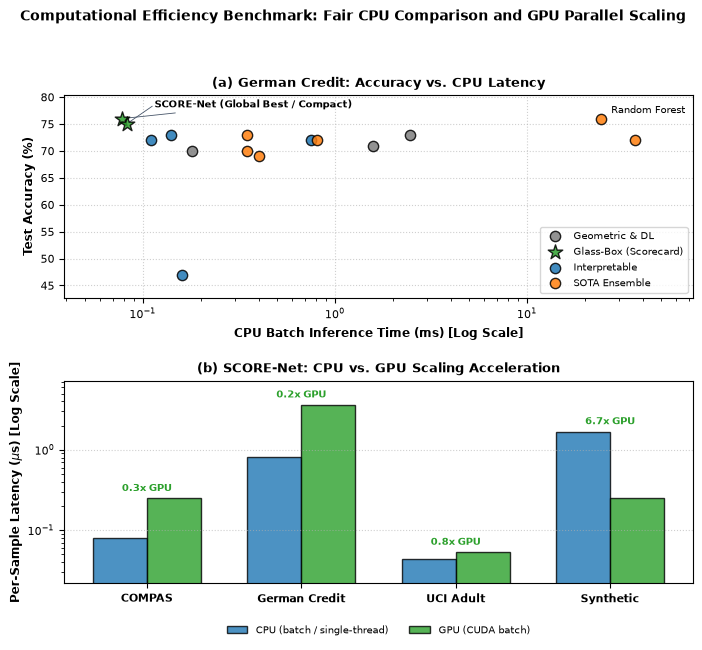

In [6]:
# ==============================================================================
# VISUALIZATION: CPU LATENCY vs. ACCURACY AND CPU/GPU SCALING
# ==============================================================================
# Rendered at text width with >= 7 pt type at print size.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.16, 6.6))

# 1. German Credit: CPU speed vs. accuracy
df_gc = combined_by_dataset["german"].dropna(
    subset=["CPU_Inference_ms", "Accuracy (%)"]
).copy()

cat_colors = {
    "Interpretable": "#1f77b4",
    "SOTA Ensemble": "#ff7f0e",
    "Geometric & DL": "#7f7f7f",
    "Glass-Box (Scorecard)": "#2ca02c",
}

for cat, group in df_gc.groupby("Category"):
    marker = "*" if "Glass-Box" in cat else "o"
    size = 120 if "Glass-Box" in cat else 55
    ax1.scatter(
        group["CPU_Inference_ms"], group["Accuracy (%)"],
        label=cat, color=cat_colors.get(cat, "blue"), s=size, marker=marker,
        edgecolors="black", alpha=0.85, zorder=5,
    )

top_models = set(df_gc.nlargest(3, "Accuracy (%)")["Model"])
label_rows = df_gc[
    df_gc["Model"].str.contains("SCORE-Net") | df_gc["Model"].isin(top_models)
]
# The two SCORE-Net points nearly coincide; separate their labels vertically.
label_offsets = {"Random Forest": (7, 4)}
for _, row in label_rows.iterrows():
    if "SCORE-Net" in row["Model"]:
        continue
    ax1.annotate(
        row["Model"].replace(" (sklearn)", ""),
        (row["CPU_Inference_ms"], row["Accuracy (%)"]),
        textcoords="offset points",
        xytext=label_offsets.get(row["Model"], (6, 4)),
        fontsize=7.5,
    )

# The two SCORE-Net points nearly overlap: one label, two thin arrows.
score_rows = label_rows[label_rows["Model"].str.contains("SCORE-Net")]
global_pt = score_rows[score_rows["Model"].str.contains("Global")].iloc[0]
compact_pt = score_rows[score_rows["Model"].str.contains("Compact")].iloc[0]
label_xy = (0.115, 78.6)
ax1.annotate(
    "SCORE-Net (Global Best / Compact)",
    (global_pt["CPU_Inference_ms"], global_pt["Accuracy (%)"]),
    xytext=label_xy, textcoords="data",
    fontsize=7.5, fontweight="bold", va="center",
    arrowprops=dict(arrowstyle="-", lw=0.6, color="#475569"),
)
ax1.annotate(
    "", (compact_pt["CPU_Inference_ms"], compact_pt["Accuracy (%)"]),
    xytext=label_xy, textcoords="data",
    arrowprops=dict(arrowstyle="-", lw=0.6, color="#475569"),
)

ax1.set_xscale("log")
positive_times = df_gc.loc[df_gc["CPU_Inference_ms"] > 0, "CPU_Inference_ms"]
if len(positive_times):
    ax1.set_xlim(positive_times.min() * 0.5, positive_times.max() * 2.0)
acc_min, acc_max = df_gc["Accuracy (%)"].min(), df_gc["Accuracy (%)"].max()
pad = max(0.5, (acc_max - acc_min) * 0.15)
ax1.set_ylim(acc_min - pad, acc_max + pad)
ax1.set_xlabel("CPU Batch Inference Time (ms) [Log Scale]", fontweight="bold", fontsize=8.5)
ax1.set_ylabel("Test Accuracy (%)", fontweight="bold", fontsize=8.5)
ax1.set_title("(a) German Credit: Accuracy vs. CPU Latency", fontweight="bold", fontsize=9.5)
ax1.tick_params(labelsize=8.0)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right", frameon=True, fontsize=7.5)

# 2. CPU vs. GPU inference profile
compact_rows = df_profiles[df_profiles["Variant"].str.contains("Compact")].copy()
datasets = compact_rows["Dataset"].tolist()
x = np.arange(len(datasets))
width = 0.35
cpu = compact_rows["CPU_Per_Sample_us"].to_numpy(dtype=float)
gpu = compact_rows["GPU_Per_Sample_us"].to_numpy(dtype=float)

ax2.bar(
    x - width / 2, cpu, width, label="CPU (batch / single-thread)",
    color="#1f77b4", edgecolor="black", alpha=0.8,
)
has_gpu = np.isfinite(gpu).any()
if has_gpu:
    ax2.bar(
        x + width / 2, gpu, width, label="GPU (CUDA batch)",
        color="#2ca02c", edgecolor="black", alpha=0.8,
    )
    for i, (cpu_val, gpu_val) in enumerate(zip(cpu, gpu)):
        if np.isfinite(gpu_val) and gpu_val > 0:
            ax2.text(
                i, max(cpu_val, gpu_val) * 1.15, f"{cpu_val / gpu_val:.1f}x GPU",
                ha="center", va="bottom", fontsize=7.5,
                fontweight="bold", color="#2ca02c",
            )
else:
    ax2.text(
        0.5, 0.95, "GPU unavailable: CPU-only profile",
        transform=ax2.transAxes, ha="center", va="top",
        fontsize=8.5, color="#991B1B",
    )

ax2.set_yscale("log")
values = cpu[np.isfinite(cpu) & (cpu > 0)]
if has_gpu:
    values = np.concatenate([values, gpu[np.isfinite(gpu) & (gpu > 0)]])
if len(values):
    ax2.set_ylim(values.min() * 0.5, values.max() * 2.0)
ax2.set_xticks(x)
ax2.set_xticklabels(datasets, fontweight="bold", fontsize=8.0)
ax2.set_ylabel(r"Per-Sample Latency ($\mu$s) [Log Scale]", fontweight="bold", fontsize=8.5)
ax2.set_title("(b) SCORE-Net: CPU vs. GPU Scaling Acceleration", fontweight="bold", fontsize=9.5)
ax2.tick_params(axis="y", labelsize=8.0)
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.16),
    ncol=2, frameon=False, fontsize=7.5,
)

plt.suptitle(
    "Computational Efficiency Benchmark: Fair CPU Comparison and GPU Parallel Scaling",
    fontweight="bold", fontsize=10.0, y=0.985,
)
plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=1.6)
save_figure(fig, "fig_inference_speed_benchmark")
plt.show()

In [7]:
# ==============================================================================
# LATEX TABLES FOR THE ACADEMIC PAPER (DYNAMIC)
# ==============================================================================
def _fmt_ms(mean, std):
    if not np.isfinite(mean):
        return "N/A"
    return f"{mean:.2f}$\\pm${std:.2f}"


table1_header = r"""\begin{table*}[t]
\centering
\caption{Computational resource profiling, rule parsimony, and dual-device (CPU vs. GPU) inference latency of \modelname{} across benchmark datasets. Latencies are averaged over $N=__N_BATCH__$ batch runs and $N=__N_SINGLE__$ single-sample ($batch=1$) runs after __N_WARMUP__ warmup iterations.}
\label{tab:computational_efficiency}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llcccccccccc}
\toprule
\textbf{Dataset} & \textbf{Model Variant} & \textbf{Test $N$} & \textbf{Acc (\%)} & \textbf{Active Rules} & \textbf{Avg Rule Len} & \textbf{Sparsity (\%)} & \textbf{Params} & \textbf{CPU Batch (ms)} & \textbf{CPU Online ($\mu$s)} & \textbf{GPU Batch (ms)} & \textbf{GPU Online ($\mu$s)} \\
\midrule
"""
table1_header = (
    table1_header
    .replace("__N_BATCH__", str(N_BATCH_RUNS))
    .replace("__N_SINGLE__", str(N_SINGLE_RUNS))
    .replace("__N_WARMUP__", str(N_WARMUP))
)

print("% ==============================================================================")
print("% LATEX TABLE 1: SCORE-NET COMPUTATIONAL EFFICIENCY AND RESOURCE PROFILE")
print("% ==============================================================================")
print(table1_header)

for _, r in df_profiles.iterrows():
    m_name = r"\modelname{} (Global)" if "Global" in r["Variant"] else r"\modelname{} (Compact)"
    print(
        f"{r['Dataset']} & {m_name} & {int(r['Test_N'])} & {r['Accuracy_%']:.2f} & "
        f"{int(r['H_active'])}/{int(r['H_init'])} & {r['Avg_Rule_Length']:.2f} & "
        f"{r['Overall_Sparsity_%']:.1f}\\% & {int(r['Active_Params'])} & "
        f"{_fmt_ms(r['CPU_Batch_ms'], r['CPU_Batch_std_ms'])} & "
        f"{_fmt_ms(r['CPU_Single_us'], r['CPU_Single_std_us'])} & "
        f"{_fmt_ms(r['GPU_Batch_ms'], r['GPU_Batch_std_ms'])} & "
        f"{_fmt_ms(r['GPU_Single_us'], r['GPU_Single_std_us'])} \\\\"
    )

print(r"""\bottomrule
\end{tabular}
}
\end{table*}
""")

# ------------------------------------------------------------------------------
# LATEX TABLE 2: GERMAN CREDIT BASELINE COMPARISON
# ------------------------------------------------------------------------------
df_gc_clean = (
    combined_by_dataset["german"]
    .dropna(subset=["Accuracy (%)", "CPU_Inference_ms"])
    .sort_values("Accuracy (%)", ascending=False)
)
german_n = int(df_profiles[df_profiles["Dataset"] == DATASETS["german"].display_name]["Test_N"].iloc[0])

table2_header = r"""\begin{table}[t]
\centering
\caption{Apples-to-apples CPU inference latency and accuracy comparison against baseline model families on the German Credit test set ($N=__N_TEST__$). All models were evaluated on the identical host CPU architecture.}
\label{tab:cpu_latency_baselines}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{llccc}
\toprule
\textbf{Model} & \textbf{Category} & \textbf{Accuracy (\%)} & \textbf{CPU Time (ms)} & \textbf{Per-Sample ($\mu$s)} \\
\midrule
""".replace("__N_TEST__", str(german_n))

print("% ==============================================================================")
print("% LATEX TABLE 2: FAIR CPU INFERENCE LATENCY COMPARISON AGAINST BASELINES")
print("% ==============================================================================")
print(table2_header)

for _, r in df_gc_clean.iterrows():
    m_fmt = f"\\textbf{{{r['Model']}}}" if "SCORE-Net" in r["Model"] else r["Model"]
    cat_escaped = str(r["Category"]).replace("&", r"\&")
    print(
        f"{m_fmt} & {cat_escaped} & {r['Accuracy (%)']:.2f} & "
        f"{r['CPU_Inference_ms']:.2f} & {r['Per_Sample_us']:.1f} \\\\"
    )

print(r"""\bottomrule
\end{tabular}
}
\end{table}
""")

% ==============================================================================
% LATEX TABLE 1: SCORE-NET COMPUTATIONAL EFFICIENCY AND RESOURCE PROFILE
% ==============================================================================
\begin{table*}[t]
\centering
\caption{Computational resource profiling, rule parsimony, and dual-device (CPU vs. GPU) inference latency of \modelname{} across benchmark datasets. Latencies are averaged over $N=100$ batch runs and $N=500$ single-sample ($batch=1$) runs after 50 warmup iterations.}
\label{tab:computational_efficiency}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llcccccccccc}
\toprule
\textbf{Dataset} & \textbf{Model Variant} & \textbf{Test $N$} & \textbf{Acc (\%)} & \textbf{Active Rules} & \textbf{Avg Rule Len} & \textbf{Sparsity (\%)} & \textbf{Params} & \textbf{CPU Batch (ms)} & \textbf{CPU Online ($\mu$s)} & \textbf{GPU Batch (ms)} & \textbf{GPU Online ($\mu$s)} \\
\midrule

COMPAS & \modelname{} (Global) & 1443 & 68.33 & 11/32 & 1.27 & 

## Verification notes

* The `H_init` and `H_active` values in the profile table come from the checkpoints and runtime compression.
* If `results/baselines_*.csv` is missing, the baseline comparison stops with a clear `FileNotFoundError`; run the corresponding baseline notebook first.
* Without a GPU, panel (b) draws a CPU-only profile and the GPU columns are reported as `N/A` in the LaTeX table.
* `SCORENET_BENCH_WARMUP`, `SCORENET_BENCH_BATCH_RUNS`, and `SCORENET_BENCH_SINGLE_RUNS` are for quick smoke tests only; manuscript numbers must use the default values.